# Murshed – Mental Health Problems Classifier

### ARTI452: Natural Language Processing
**Imam Abdulrahman Bin Faisal University**  
College of Computer Science and Information Technology

### Team Members

| Student Name | Student ID | 
|---|---|
| Aleen Alzahrani | 2240006885 | 
| Najaf Almohsen | 2240003480 | 
| Haya Alwuhaibi | 2240007544 |

## Project Overview

Murshed is an Arabic Natural Language Processing (NLP) system designed to classify mental health consultation questions into six predefined categories. The system aims to help users identify a relevant mental health support category based on their written questions.

Two classification methods are implemented and compared:

1. **Semantic Similarity + K-Nearest Neighbours (KNN)**
2. **TF-IDF + Linear Support Vector Machine (SVM)**

## 1. Environment Setup and Libraries

### 1.1 Install & Import Required Libraries

In [171]:
#%pip install -q pandas numpy matplotlib seaborn scikit-learn nltk openpyxl

In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import unicodedata
import html
from collections import Counter

from pathlib import Path

import nltk
from nltk.corpus import stopwords
from nltk.stem.isri import ISRIStemmer

from sklearn.model_selection import train_test_split

from IPython.display import display

import random

nltk.download("stopwords", quiet=True)

True

### 1.2 Configuration and Reproducibility

In [173]:
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DATA_DIR = Path("Dataset")
OUTPUT_DIR = Path("processed_data")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

print("Dataset directory:", DATA_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

assert DATA_DIR.exists(), "Dataset folder not found."

Dataset directory: C:\Users\hayaa\OneDrive - IMAM ABDULRAHMAN BIN FAISAL UNIVERSITY\كلية الحاسب\Senior Year 2026-2027\1st Semester\Natural_Language_Processing\NLP_project\Dataset
Output directory: C:\Users\hayaa\OneDrive - IMAM ABDULRAHMAN BIN FAISAL UNIVERSITY\كلية الحاسب\Senior Year 2026-2027\1st Semester\Natural_Language_Processing\NLP_project\processed_data


## 2. Data Acquisition and Preprocessing

### 2.1 Dataset Loading

In [174]:
# Find and list all CSV files in the dataset directory
csv_files = sorted(DATA_DIR.glob("*.csv"))

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)

if not csv_files:
    raise FileNotFoundError("No CSV files found.")

Number of CSV files: 7
Behavioral_Psychological_Conditions.csv
Childhood_Psychological_Problems.csv
Neuropsychological_Conditions.csv
Other_Psychological_and_Behavioral_Issues.csv
Personality_and_Self_Development.csv
Psychological_Issues_and_Guidance.csv
Psychotic_Disorders.csv


In [175]:
# Read CSV files and inspect their columns and sample rows
def read_csv_file(path, nrows=None):
    for encoding in ["utf-8-sig", "utf-8", "cp1256"]:
        try:
            return pd.read_csv(
                path,
                encoding=encoding,
                nrows=nrows
            )
        except UnicodeDecodeError:
            continue

    raise ValueError(f"Unable to decode: {path.name}")


for file in csv_files:
    sample = read_csv_file(file, nrows=3)

    print("\n" + "=" * 60)
    print("File:", file.name)
    print("Columns:", sample.columns.tolist())

    display(sample.head(2))


File: Behavioral_Psychological_Conditions.csv
Columns: ['Question Title', 'Question', 'Answer', 'Doctor Name', 'Consultation Number', 'Date of Answer', 'Hierarchical Diagnosis']


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis
0,أتعبتني الخيالات الانفعالية، فما هو العلاج؟,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,بسم الله الرحمن الرحيم\nالأخ الفاضل/ محمد حفظه الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك في إسلام ويب...,د. محمد عبد العليم,2550657,2024-10-15,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة
1,أعيش في الخيال أكثر من الواقع، فكيف أتخلص من ذلك؟,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، عمري 17 سنة، منذ صغري وأنا أعاني من الخيال بشكل مفرط، وأتخيل شخصيات ال...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ نور حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nحقيقةً قرأتُ سؤالك...,د. مأمون مبيض,2544364,2024-06-27,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة



File: Childhood_Psychological_Problems.csv
Columns: ['Question Title', 'Question', 'Answer', 'Doctor Name', 'Consultation Number', 'Date of Answer', 'Hierarchical Diagnosis']


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis
0,أحتاج لتوجيهكم بشأن الروضة التي تناسب ابنتي أكثر..,السلام عليكم ورحمة الله وبركاته.\n\nابنتي عمرها 4 سنوات، وأريد البحث عن روضة مناسبة لها، من حيث المكان، والاهتمام، و...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ مريم حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنتفهم تمامًا مخاو...,أ. فيصل العشاري,2545743,2024-07-24,مشاكل الطفل النفسية - أمور أخرى متعلقة بالصحة النفسية للطفل
1,كيف أعود طفلي على الذهاب إلى الحمام بنفسه؟,ابني بعمر سنتين وعشرة أشهر، بدأت في تعليمه استعمال الحمام قبل سبعة أشهر، وإلى اليوم لا يطلب مني الذهاب إلى الحمام، و...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ سائلة حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nيجب ألا يقترن ال...,د. عطية إبراهيم محمد,2546073,2024-07-21,مشاكل الطفل النفسية - أمور أخرى متعلقة بالصحة النفسية للطفل



File: Neuropsychological_Conditions.csv
Columns: ['Question Title', 'Question', 'Answer', 'Doctor Name', 'Consultation Number', 'Date of Answer', 'Hierarchical Diagnosis']


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis
0,أشعر بالاكتئاب في الصباح وأتحسن في المغرب.. ما العلة؟,السلام عليكم.\n\nعمري 16 سنة، كنت مريضًا بالوسواس القهري في شهر 6، فذهبت للطبيبة النفسية فكتبت لي (Faverin 100)، حبت...,بسم الله الرحمن الرحيم\nالأخ الفاضل/ zeyad حفظه الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك في استشارات...,د. محمد عبد العليم,2551445,2024-11-17,الحالات النفسية العصبية - الاكتئاب - الاكتئاب عمومًا
1,هل يمكن الجمع بين إنفرانيل وسيبرالكس لعلاج الاكتئاب والهلع؟,السلام عليكم ورحمة الله وبركاته\n\nأعاني من الاكتئاب ونوبات الفزع، ووصف لي الطبيب: الإنفرانيل 25 ملغ، والسيبرالكس 15...,بسم الله الرحمن الرحيم\nالأخ الفاضل/ إبراهيم حفظه الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك -أخي الفا...,د. مأمون مبيض,2551317,2024-11-10,الحالات النفسية العصبية - الاكتئاب - الاكتئاب عمومًا


... (4 outputs left out)


File: Psychological_Issues_and_Guidance.csv
Columns: ['Question Title', 'Question', 'Answer', 'Doctor Name', 'Consultation Number', 'Date of Answer', 'Hierarchical Diagnosis']


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis
0,ذكرياتي المزعجة تداهمني عند الاستيقاظ وتفسد صباحي، فماذا أفعل؟,السلام عليكم ورحمة الله وبركاته\n\nهناك شيء يحدث معي منذ فترة طويلة في الصباح، وقبل الاستيقاظ من النوم بقليل، حينما ...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ أمل حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك في إسلام و...,د. محمد عبد العليم,2549369,2024-09-17,قضايا وإرشادات نفسية عامة - أخرى
1,هل يمكن دراسة علم النفس عن طريق الكتب فقط؟,السلام عليكم ورحمة الله وبركاته\n\nأسأل: ما هي طريق الوصول لفهم وتحليل الشخصيات والمشاكل النفسية، وفهم النفس وطريقة ...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ بنية حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك -بُنيَّتي...,د. مأمون مبيض,2547801,2024-08-25,قضايا وإرشادات نفسية عامة - أخرى



File: Psychotic_Disorders.csv
Columns: ['Question Title', 'Question', 'Answer', 'Doctor Name', 'Consultation Number', 'Date of Answer', 'Hierarchical Diagnosis']


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis
0,زميلي يشكو من أعراض الذهان الجانبية، فكيف يتخلص منها؟,السلام عليكم ورحمة الله وبركاته.\n\nسؤالي له بعد طبي وشرعي: هنالك شاب في العشرين من عمره، وتعرض لمشاكل نفسية أثرت عل...,بسم الله الرحمن الرحيم\nالأخ الفاضل/ عبد الرحمن حفظه الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك في إسل...,د. محمد عبد العليم,2549762,2024-09-24,الأمراض الذهانية - أمور أخرى متعلقة بالأمراض الذهانية
1,لا أشعر بالرضا عن حياتي ولا علاقتي بربي، فماذا أفعل؟,السلام عليكم.\n\nأشعر بأني تائهة في الحياة، ولا أعرف من أين أبدأ! لا أشعر بالرضا عن حياتي، ولا علاقتي بربي، ولا علاق...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ Sa. حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك -أختنا الف...,د. مأمون مبيض,2547156,2024-08-07,الأمراض الذهانية - أمور أخرى متعلقة بالأمراض الذهانية


In [176]:
# The 6 selected CSV files
selected_files = [
    "Behavioral_Psychological_Conditions.csv",
    "Neuropsychological_Conditions.csv",
    "Personality_and_Self_Development.csv",
    "Psychotic_Disorders.csv",
    "Childhood_Psychological_Problems.csv",
    "Other_Psychological_and_Behavioral_Issues.csv"
]

# List to store DataFrames
all_data = []

# Loop through the 6 files
for file_name in selected_files:

    file_path = DATA_DIR / file_name
    df = read_csv_file(file_path)

    # Extract category from filename
    category = file_path.stem.replace("_", " ")

    # Add Category column
    df["Category"] = category

    # Add DataFrame to the list
    all_data.append(df)

    print(f"Loaded: {file_name} | Category: {category} | Rows: {len(df)}")

# Merge all 6 DataFrames
merged_df = pd.concat(all_data, ignore_index=True)

# Save merged dataset
merged_df.to_csv(
    OUTPUT_DIR / "Murshed_Dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Final Dataset Shape:", merged_df.shape)

display(merged_df.head())

Loaded: Behavioral_Psychological_Conditions.csv | Category: Behavioral Psychological Conditions | Rows: 2705
Loaded: Neuropsychological_Conditions.csv | Category: Neuropsychological Conditions | Rows: 24835
Loaded: Personality_and_Self_Development.csv | Category: Personality and Self Development | Rows: 4558
Loaded: Psychotic_Disorders.csv | Category: Psychotic Disorders | Rows: 1738
Loaded: Childhood_Psychological_Problems.csv | Category: Childhood Psychological Problems | Rows: 690
Loaded: Other_Psychological_and_Behavioral_Issues.csv | Category: Other Psychological and Behavioral Issues | Rows: 262
Final Dataset Shape: (34788, 8)


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis,Category
0,أتعبتني الخيالات الانفعالية، فما هو العلاج؟,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,بسم الله الرحمن الرحيم\nالأخ الفاضل/ محمد حفظه الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك في إسلام ويب...,د. محمد عبد العليم,2550657,2024-10-15,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة,Behavioral Psychological Conditions
1,أعيش في الخيال أكثر من الواقع، فكيف أتخلص من ذلك؟,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، عمري 17 سنة، منذ صغري وأنا أعاني من الخيال بشكل مفرط، وأتخيل شخصيات ال...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ نور حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nحقيقةً قرأتُ سؤالك...,د. مأمون مبيض,2544364,2024-06-27,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة,Behavioral Psychological Conditions
2,ما هو علاج الأفكار والخيالات الوسواسية التي تسيطر علي؟,السلام عليكم ورحمة الله وبركاته.\n\nأنا طالبة عمري 17، لما كنت صغيرة كنت أعاني من التنمُّر، وبسبب هذا صرت أتخيل شخصي...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ نور حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nأولًا: الحمد لله أ...,د. على أحمد التهامي,2543834,2024-06-23,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة,Behavioral Psychological Conditions
3,تخيلاتي المفرطة لدرجة الهوس تشعرني بالجنون!,السلام عليكم ورحمة الله وبركاته.\n\nأعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأن...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ Dihia حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nالخيال هو وسيلة ...,د. عبدالمنعم محمود عبدالحكم,2541965,2024-06-03,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة,Behavioral Psychological Conditions
4,أعيش في أحلام اليقظة وإدمانها، فكيف أعود للواقع؟,السلام عليكم ورحمة الله وبركاته\n\nأعاني من أحلام اليقظة المرضية وإدمانها، وكنت أعاني من هذه المشكلة منذ الإعدادية، ...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ رقية حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nمرحبًا بك في استش...,د. على أحمد التهامي,2541396,2024-05-27,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة,Behavioral Psychological Conditions


In [177]:
# Verify the merged dataset and category distribution
print("Total Rows:", len(merged_df))
print("Number of Categories:", merged_df["Category"].nunique())

print("\nRows per Category:")
print(merged_df["Category"].value_counts())

Total Rows: 34788
Number of Categories: 6

Rows per Category:
Category
Neuropsychological Conditions                24835
Personality and Self Development              4558
Behavioral Psychological Conditions           2705
Psychotic Disorders                           1738
Childhood Psychological Problems               690
Other Psychological and Behavioral Issues      262
Name: count, dtype: int64


**Note:** Since the **Question** column will be used as the input for our classification models, we will focus our data analysis and preprocessing on this column to ensure data quality before training.

### 2.2 Exploratory Data Analysis (EDA)

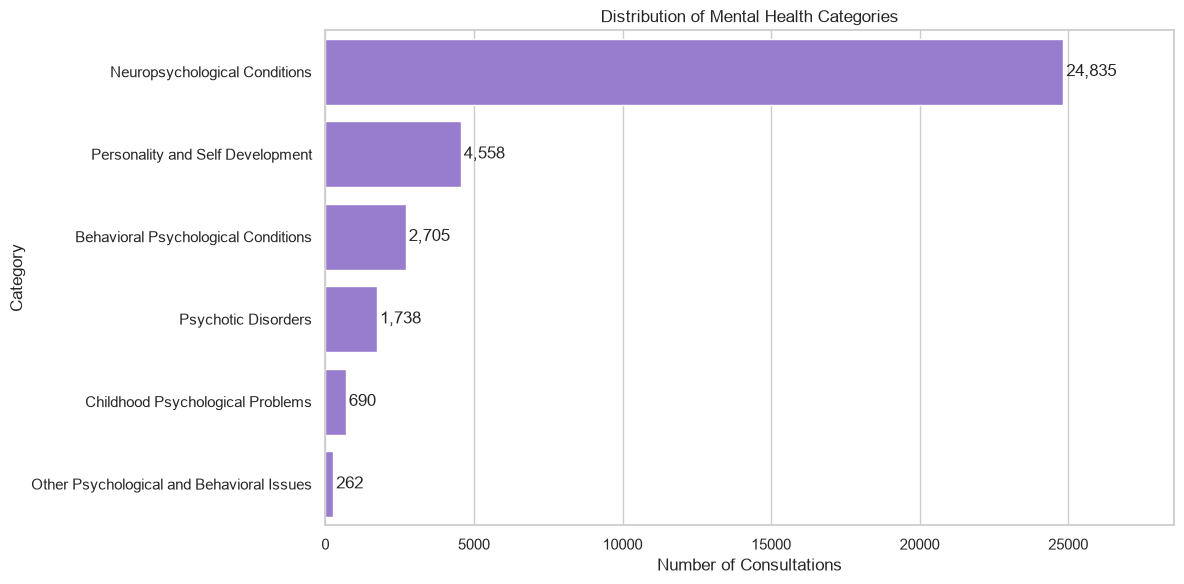

In [178]:
# Visualize the distribution of the six categories
plt.figure(figsize=(12, 6))

category_counts = merged_df["Category"].value_counts()

ax = sns.barplot(
    x=category_counts.values,
    y=category_counts.index,
    color="mediumpurple"
)

for i, count in enumerate(category_counts.values):
    ax.text(count + 100, i, f"{count:,}", va="center")

plt.title("Distribution of Mental Health Categories")
plt.xlabel("Number of Consultations")
plt.ylabel("Category")
plt.xlim(0, category_counts.max() * 1.15)
plt.tight_layout()
plt.show()

The dataset contains **34,788 consultations** across six categories. However, the data is highly imbalanced, with **Neuropsychological Conditions** representing the majority of the samples (24,835), while **Other Psychological and Behavioral Issues** has only 262 samples.

This imbalance may cause the models to favor the majority class. Therefore, **Macro F1-score** will be used alongside accuracy to evaluate performance across all categories.

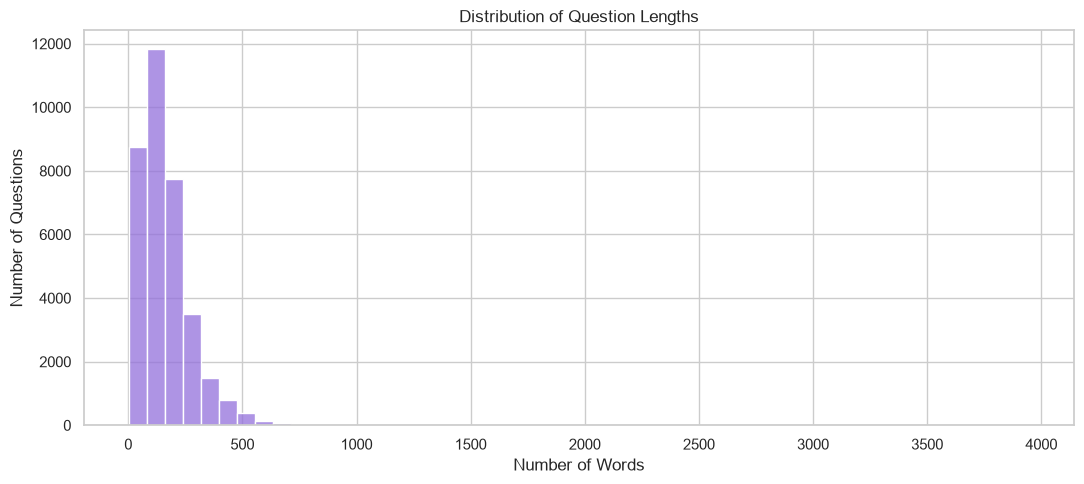

Average Question Length: 163.35
Median Question Length: 137.0
Minimum Question Length: 5
Maximum Question Length: 3946


In [179]:
# Analyze question lengths based on word count
merged_df["Question_Length"] = (merged_df["Question"].astype(str).str.split().str.len())

plt.figure(figsize=(11, 5))

sns.histplot(
    data=merged_df,
    x="Question_Length",
    bins=50,
    color="mediumpurple"
)

plt.title("Distribution of Question Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Questions")
plt.tight_layout()
plt.show()

print("Average Question Length:", round(merged_df["Question_Length"].mean(), 2))
print("Median Question Length:", merged_df["Question_Length"].median())
print("Minimum Question Length:", merged_df["Question_Length"].min())
print("Maximum Question Length:", merged_df["Question_Length"].max())

The average question length is **163.35 words**, while the median is **137 words**. Most questions are relatively short compared to the longest question, which contains **3,946 words**.

The distribution is right-skewed, indicating the presence of unusually long questions. This variation in question length is important for evaluating how well the classification models handle different input lengths.

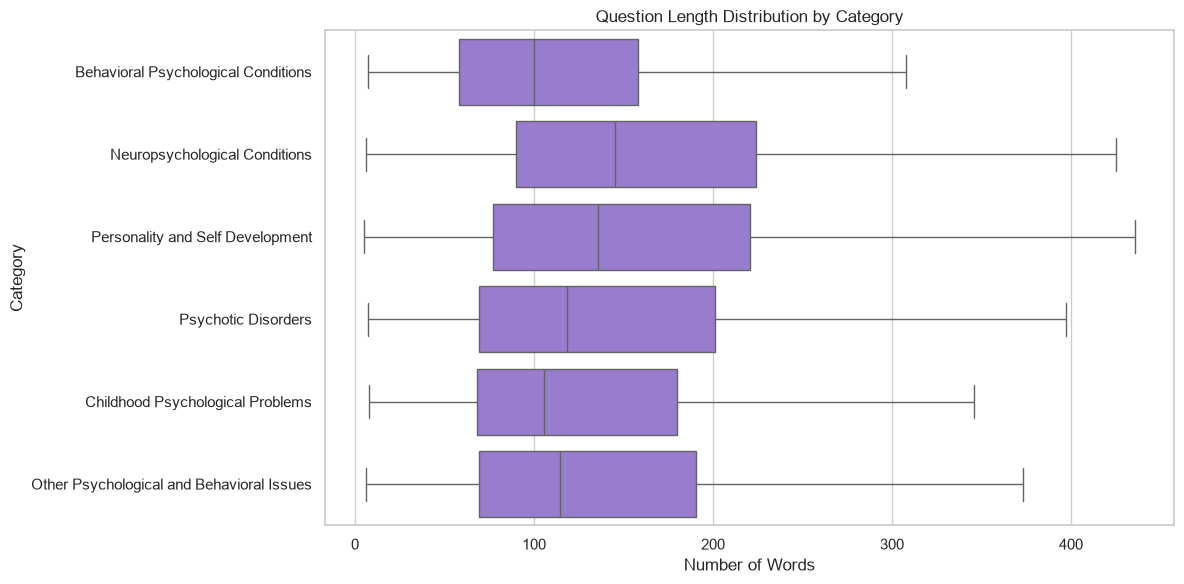

In [180]:
# Compare question lengths across the six categories
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=merged_df,
    x="Question_Length",
    y="Category",
    color="mediumpurple",
    showfliers=False
)

plt.title("Question Length Distribution by Category")
plt.xlabel("Number of Words")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

The boxplot shows that question lengths vary across the six categories. **Neuropsychological Conditions** has the highest median question length, while **Behavioral Psychological Conditions** tends to have shorter questions.

Although the distributions overlap, some categories show greater variation in question length. This suggests that question length may influence classification performance and should be considered during model evaluation.

### 2.3 Data Cleaning

In [181]:
# Check missing values and duplicate questions
print("Dataset Shape:", merged_df.shape)

print("\nMissing Questions:")
print(merged_df["Question"].isna().sum())

print("\nEmpty Questions:")
print(merged_df["Question"].fillna("").str.strip().eq("").sum())

print("\nDuplicate Questions:")
print(merged_df["Question"].duplicated().sum())

print("\nMissing Values per Column:")
display(merged_df.isna().sum())

Dataset Shape: (34788, 9)

Missing Questions:
0

Empty Questions:
0

Duplicate Questions:
12085

Missing Values per Column:


Question Title            0
Question                  0
Answer                    0
Doctor Name               0
Consultation Number       0
Date of Answer            0
Hierarchical Diagnosis    0
Category                  0
Question_Length           0
dtype: int64

The dataset contains **12,085 duplicate rows based on the Question column**, representing approximately **34.7%** of the total dataset.

Duplicate questions may affect model evaluation and cause data leakage if they appear in both training and testing sets. Therefore, duplicates will be examined, including checking for conflicting category labels, before cleaning and splitting the dataset.

In [182]:
# Count questions appearing more than once
duplicate_counts = merged_df["Question"].value_counts()

print("Unique Questions:", merged_df["Question"].nunique())
print("Repeated Questions:", (duplicate_counts > 1).sum())
print("Extra Duplicate Rows:", merged_df["Question"].duplicated().sum())

# Check if the same question belongs to multiple categories
category_counts = merged_df.groupby("Question")["Category"].nunique()

conflicting_questions = category_counts[category_counts > 1]

print("\nQuestions with Conflicting Labels:", len(conflicting_questions))

# Display examples of conflicting labels
if len(conflicting_questions) > 0:
    conflicting_examples = merged_df[
        merged_df["Question"].isin(conflicting_questions.index)
    ][["Question", "Category"]]

    display(conflicting_examples.sort_values("Question").head(10))
else:
    print("No conflicting labels found.")

Unique Questions: 22703
Repeated Questions: 8682
Extra Duplicate Rows: 12085

Questions with Conflicting Labels: 1638


,Question,Category
833,أبلغ من العمر 24 عامًا، وقد كنت في الصغر أنا وإخواني من المتفوقين دراسيًا، والعائلة كانت فخورة بنا، وكانت الحالة الم...,Behavioral Psychological Conditions
15779,أبلغ من العمر 24 عامًا، وقد كنت في الصغر أنا وإخواني من المتفوقين دراسيًا، والعائلة كانت فخورة بنا، وكانت الحالة الم...,Neuropsychological Conditions
16768,أبلغ من العمر 24 عامًا، وقد كنت في الصغر أنا وإخواني من المتفوقين دراسيًا، والعائلة كانت فخورة بنا، وكانت الحالة الم...,Neuropsychological Conditions
1688,"أبلغ من العمر 29 سنة، وأعاني من قولون عصبي, ويسبب لي أرقا عند النوم أحيانا، فلا أستطيع النوم؛ لأني عندما أريد النوم ...",Behavioral Psychological Conditions
13130,"أبلغ من العمر 29 سنة، وأعاني من قولون عصبي, ويسبب لي أرقا عند النوم أحيانا، فلا أستطيع النوم؛ لأني عندما أريد النوم ...",Neuropsychological Conditions
15790,أبلغ من العمر 40 عامًا، عملت في مجال القانون منذ 19 عامًا تقريبًا، خلال سنوات عملي بهذا المجال ينصرف جلّ تفكيري حول ...,Neuropsychological Conditions
30187,أبلغ من العمر 40 عامًا، عملت في مجال القانون منذ 19 عامًا تقريبًا، خلال سنوات عملي بهذا المجال ينصرف جلّ تفكيري حول ...,Personality and Self Development
31512,أبلغ من العمر 40 عامًا، عملت في مجال القانون منذ 19 عامًا تقريبًا، خلال سنوات عملي بهذا المجال ينصرف جلّ تفكيري حول ...,Personality and Self Development
2322,أتوجه بالشكر الكبير لكل العاملين في هذا الموقع.\n\nأنا أعاني منذ الصغر من سوء معاملة والدي لي، فقد كنت منذ الصغر أتع...,Behavioral Psychological Conditions
32410,أتوجه بالشكر الكبير لكل العاملين في هذا الموقع.\n\nأنا أعاني منذ الصغر من سوء معاملة والدي لي، فقد كنت منذ الصغر أتع...,Psychotic Disorders


In [183]:
# Analyze conflicting labels before removing any data
conflicting_mask = merged_df["Question"].isin(conflicting_questions.index)

conflicting_df = merged_df[conflicting_mask]

print("Questions with Conflicting Labels:", len(conflicting_questions))
print("Total Rows with Conflicting Labels:", len(conflicting_df))

print("\nAffected Rows per Category:")
display(conflicting_df["Category"].value_counts())

print("\nRemaining Rows if Conflicts Are Removed:")
print(len(merged_df) - len(conflicting_df))

Questions with Conflicting Labels: 1638
Total Rows with Conflicting Labels: 4131

Affected Rows per Category:


Category
Neuropsychological Conditions                1867
Personality and Self Development             1130
Behavioral Psychological Conditions           617
Psychotic Disorders                           378
Other Psychological and Behavioral Issues      88
Childhood Psychological Problems               51
Name: count, dtype: int64


Remaining Rows if Conflicts Are Removed:
30657


During data analysis, we identified **1,638 unique questions assigned to multiple categories**.

Since the **Question** column is the only input to our classification models, these conflicting labels introduce ambiguity into the training data.

We will examine the affected samples and their category distribution before removing conflicting questions and duplicate entries to improve data consistency and reduce the risk of data leakage.

In [184]:
# Save conflicting questions for further analysis
conflicting_df.to_csv(
    OUTPUT_DIR / "Murshed_Conflicting_Questions.csv",
    index=False,
    encoding="utf-8-sig"
)

# Remove questions with conflicting labels
cleaned_df = merged_df[~merged_df["Question"].isin(conflicting_questions.index)].copy()

print("Rows after removing conflicting labels:", len(cleaned_df))

# Remove duplicate questions
cleaned_df = cleaned_df.drop_duplicates(
    subset=["Question"],
    keep="first"
).reset_index(drop=True)

print("Rows after removing duplicates:", len(cleaned_df))

# Keep only the required columns
cleaned_df = cleaned_df[["Question", "Category"]].copy()

# Check category distribution
print("\nCategory Distribution After Cleaning:")
display(cleaned_df["Category"].value_counts())

# Save cleaned dataset
cleaned_df.to_csv(
    OUTPUT_DIR / "Murshed_Cleaned_Dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nFinal Dataset Shape:", cleaned_df.shape)

Rows after removing conflicting labels: 30657
Rows after removing duplicates: 21065

Category Distribution After Cleaning:


Category
Neuropsychological Conditions                15260
Personality and Self Development              2297
Behavioral Psychological Conditions           1723
Psychotic Disorders                           1133
Childhood Psychological Problems               491
Other Psychological and Behavioral Issues      161
Name: count, dtype: int64


Final Dataset Shape: (21065, 2)


After removing conflicting labels and exact duplicate questions, the dataset was reduced from **34,788 to 21,065 unique questions**.

The cleaned dataset contains two columns: `Question` and `Category`, with six classification categories.

Although duplicates and conflicting labels were removed, the dataset remains highly imbalanced, with **Neuropsychological Conditions** representing the majority of the samples.

In [185]:
# Verify the cleaned dataset
print("Final Dataset Shape:", cleaned_df.shape)

print("Missing Questions:", cleaned_df["Question"].isna().sum())
print("Empty Questions:", cleaned_df["Question"].str.strip().eq("").sum())
print("Duplicate Questions:", cleaned_df["Question"].duplicated().sum())

print("Number of Categories:", cleaned_df["Category"].nunique())

print("Conflicting Labels:", (cleaned_df.groupby("Question")["Category"].nunique() > 1).sum())

display(cleaned_df.head())

Final Dataset Shape: (21065, 2)
Missing Questions: 0
Empty Questions: 0
Duplicate Questions: 0
Number of Categories: 6
Conflicting Labels: 0


,Question,Category
0,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,Behavioral Psychological Conditions
1,السلام عليكم ورحمة الله وبركاته.\n\nأعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأن...,Behavioral Psychological Conditions
2,السلام عليكم.\n\nأنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنو...,Behavioral Psychological Conditions
3,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقت...,Behavioral Psychological Conditions
4,السلام عليكم ورحمة الله وبركاته.\n\nكنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي!\n\nاسمي أسماء، عمري...,Behavioral Psychological Conditions


### 2.4 Arabic Text Preprocessing

In [186]:
# Basic text cleaning 
def basic_cleaning(text):
    text = html.unescape(str(text))
    text = unicodedata.normalize("NFC", text)

    # Remove URLs and HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove tatweel
    text = text.replace("ـ", "")

    # Replace line breaks and tabs
    text = text.replace("\\n", " ")
    text = re.sub(r"[\r\n\t]+", " ", text)

    # Remove invisible formatting characters
    text = re.sub(r"[\u200B-\u200D\uFEFF]", "", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

cleaned_df["Basic_Question"] = (cleaned_df["Question"].apply(basic_cleaning))

display(cleaned_df[["Question", "Basic_Question"]].head())

,Question,Basic_Question
0,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,السلام عليكم ورحمة الله وبركاته أعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر بان...
1,السلام عليكم ورحمة الله وبركاته.\n\nأعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأن...,السلام عليكم ورحمة الله وبركاته. أعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأني ب...
2,السلام عليكم.\n\nأنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنو...,السلام عليكم. أنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...
3,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقت...,السلام عليكم ورحمة الله وبركاته. أنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقتي ف...
4,السلام عليكم ورحمة الله وبركاته.\n\nكنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي!\n\nاسمي أسماء، عمري...,السلام عليكم ورحمة الله وبركاته. كنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي! اسمي أسماء، عمري ١٩ سن...


In [187]:
# Arabic normalization 
def normalize_arabic(text):
    # Remove Arabic diacritics
    text = re.sub(r"[\u064B-\u065F\u0670]", "", text)

    # Normalize Alef forms
    text = re.sub(r"[أإآٱ]", "ا", text)

    return text

cleaned_df["Normalized_Question"] = (cleaned_df["Basic_Question"].apply(normalize_arabic))

display(cleaned_df[["Question", "Basic_Question", "Normalized_Question"]].head())

,Question,Basic_Question,Normalized_Question
0,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,السلام عليكم ورحمة الله وبركاته أعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر بان...,السلام عليكم ورحمة الله وبركاته اعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي او شجاري مع شخص ما، واشعر بان...
1,السلام عليكم ورحمة الله وبركاته.\n\nأعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأن...,السلام عليكم ورحمة الله وبركاته. أعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأني ب...,السلام عليكم ورحمة الله وبركاته. اعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرات قصة من صنع الخيال، كاني ب...
2,السلام عليكم.\n\nأنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنو...,السلام عليكم. أنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,السلام عليكم. انا فتاة، بعمر 22 سنة، ادرس في الجامعة، اعاني من احلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...
3,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقت...,السلام عليكم ورحمة الله وبركاته. أنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقتي ف...,السلام عليكم ورحمة الله وبركاته. انا فتاة، ابلغ من العمر 19 سنة، اعاني من التحدث مع نفسي، مثلا: اذا كنت مع صديقتي في...
4,السلام عليكم ورحمة الله وبركاته.\n\nكنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي!\n\nاسمي أسماء، عمري...,السلام عليكم ورحمة الله وبركاته. كنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي! اسمي أسماء، عمري ١٩ سن...,السلام عليكم ورحمة الله وبركاته. كنت مترددة ان اتكلم عن مشكلتي، الا ان الموضوع خرج عن سيطرتي! اسمي اسماء، عمري ١٩ سن...


In [188]:
# Tokenize normalized Arabic text
def tokenize_arabic(text):
    return re.findall(r"\w+", text, flags=re.UNICODE)

cleaned_df["Tokens"] = (cleaned_df["Normalized_Question"].apply(tokenize_arabic))

display(cleaned_df[["Normalized_Question", "Tokens"]].head())

,Normalized_Question,Tokens
0,السلام عليكم ورحمة الله وبركاته اعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي او شجاري مع شخص ما، واشعر بان...,"[السلام, عليكم, ورحمة, الله, وبركاته, اعاني, منذ, سنوات, من, تخيل, بعض, المواقف, في, ذهني, حول, خلافي, او, شجاري, مع..."
1,السلام عليكم ورحمة الله وبركاته. اعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرات قصة من صنع الخيال، كاني ب...,"[السلام, عليكم, ورحمة, الله, وبركاته, اعاني, من, تخيلات, مفرطة, لدرجة, الهوس, فعلى, سبيل, المثال, قرات, قصة, من, صنع..."
2,السلام عليكم. انا فتاة، بعمر 22 سنة، ادرس في الجامعة، اعاني من احلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,"[السلام, عليكم, انا, فتاة, بعمر, 22, سنة, ادرس, في, الجامعة, اعاني, من, احلام, اليقظة, المفرطة, منذ, سنين, عديدة, ول..."
3,السلام عليكم ورحمة الله وبركاته. انا فتاة، ابلغ من العمر 19 سنة، اعاني من التحدث مع نفسي، مثلا: اذا كنت مع صديقتي في...,"[السلام, عليكم, ورحمة, الله, وبركاته, انا, فتاة, ابلغ, من, العمر, 19, سنة, اعاني, من, التحدث, مع, نفسي, مثلا, اذا, ك..."
4,السلام عليكم ورحمة الله وبركاته. كنت مترددة ان اتكلم عن مشكلتي، الا ان الموضوع خرج عن سيطرتي! اسمي اسماء، عمري ١٩ سن...,"[السلام, عليكم, ورحمة, الله, وبركاته, كنت, مترددة, ان, اتكلم, عن, مشكلتي, الا, ان, الموضوع, خرج, عن, سيطرتي, اسمي, ا..."


In [189]:
# Remove Arabic stopwords
arabic_stopwords = set(stopwords.words("arabic"))

negations = {
    "لا", "ما", "لم", "لن", "ليس", "ليست",
    "مش", "مو", "مب", "ماني", "بدون", "غير"
}

arabic_stopwords -= negations

def remove_stopwords(tokens):
    return [
        word for word in tokens
        if word not in arabic_stopwords
    ]

cleaned_df["Tokens_No_Stopwords"] = (cleaned_df["Tokens"].apply(remove_stopwords))

cleaned_df["TFIDF_No_Stopwords"] = (cleaned_df["Tokens_No_Stopwords"].apply(" ".join))

display(cleaned_df[["Normalized_Question", "TFIDF_No_Stopwords"]].head())

,Normalized_Question,TFIDF_No_Stopwords
0,السلام عليكم ورحمة الله وبركاته اعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي او شجاري مع شخص ما، واشعر بان...,السلام عليكم ورحمة الله وبركاته اعاني سنوات تخيل المواقف ذهني حول خلافي او شجاري شخص ما واشعر بانفعال شديد بسبب الخي...
1,السلام عليكم ورحمة الله وبركاته. اعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرات قصة من صنع الخيال، كاني ب...,السلام عليكم ورحمة الله وبركاته اعاني تخيلات مفرطة لدرجة الهوس فعلى سبيل المثال قرات قصة صنع الخيال كاني بطلة القصة ...
2,السلام عليكم. انا فتاة، بعمر 22 سنة، ادرس في الجامعة، اعاني من احلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,السلام عليكم انا فتاة بعمر 22 سنة ادرس الجامعة اعاني احلام اليقظة المفرطة سنين عديدة السنوات الثلاث الاخيرة ساءت حال...
3,السلام عليكم ورحمة الله وبركاته. انا فتاة، ابلغ من العمر 19 سنة، اعاني من التحدث مع نفسي، مثلا: اذا كنت مع صديقتي في...,السلام عليكم ورحمة الله وبركاته انا فتاة ابلغ العمر 19 سنة اعاني التحدث نفسي مثلا اذا كنت صديقتي مكان اتخيل راسي اشي...
4,السلام عليكم ورحمة الله وبركاته. كنت مترددة ان اتكلم عن مشكلتي، الا ان الموضوع خرج عن سيطرتي! اسمي اسماء، عمري ١٩ سن...,السلام عليكم ورحمة الله وبركاته كنت مترددة ان اتكلم مشكلتي الا ان الموضوع خرج سيطرتي اسمي اسماء عمري ١٩ سنة عندي مشك...


In [190]:
# Experimental stemming using ISRIStemmer
stemmer = ISRIStemmer()

def stem_tokens(tokens):
    return [stemmer.stem(word) for word in tokens]

cleaned_df["Stemmed_Tokens"] = (cleaned_df["Tokens_No_Stopwords"].apply(stem_tokens))

cleaned_df["TFIDF_Stemmed"] = (cleaned_df["Stemmed_Tokens"].apply(" ".join))

display(cleaned_df[["Normalized_Question", "TFIDF_Stemmed"]].head())

,Normalized_Question,TFIDF_Stemmed
0,السلام عليكم ورحمة الله وبركاته اعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي او شجاري مع شخص ما، واشعر بان...,سلم علي رحم الل وبر اعا سنو تخل وقف ذهن حول خلف او شجر شخص ما شعر فعل شدد سبب خيل درج تصل الى رفع عدل ضرب قلب شكل لح...
1,السلام عليكم ورحمة الله وبركاته. اعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرات قصة من صنع الخيال، كاني ب...,سلم علي رحم الل وبر اعا تخل فرط درج هوس على سبل ثال قرت قصة صنع خيل كني بطل قصة وصر وقف كنه معي او غير وبد نسج خيل ا...
2,السلام عليكم. انا فتاة، بعمر 22 سنة، ادرس في الجامعة، اعاني من احلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,سلم علي انا فتة عمر 22 سنة درس جمع اعا حلم يقظ فرط سنن عدد سنو ثلث خير سءت حلت صبح فشل درس بعد كنت تفف ان علق صبح سي...
3,السلام عليكم ورحمة الله وبركاته. انا فتاة، ابلغ من العمر 19 سنة، اعاني من التحدث مع نفسي، مثلا: اذا كنت مع صديقتي في...,سلم علي رحم الل وبر انا فتة بلغ عمر 19 سنة اعا حدث نفس ثلا اذا كنت صدق كان تخل رسي شيء حدث دخل بقى حدث وقت طول عند ا...
4,السلام عليكم ورحمة الله وبركاته. كنت مترددة ان اتكلم عن مشكلتي، الا ان الموضوع خرج عن سيطرتي! اسمي اسماء، عمري ١٩ سن...,سلم علي رحم الل وبر كنت تردد ان كلم شكل الا ان وضع خرج يطر اسم سمء عمر ١٩ سنة عند شكل بدن بلغ دمر لحا حلم يقظ فرط شك...



<p style="color: red;"><strong>Group Note:</strong> I found ISRIStemmer used in another Arabic NLP project, so I added it as an experiment. However, I noticed that some words changed significantly and might lose their original meaning. I'm not sure if stemming is suitable for our project, so we should discuss whether to keep it or not.</p>


### 2.5 Prepare Separate Text Versions For Both Models

In [191]:
# Arabic-SBERT: minimal cleaning
cleaned_df["SBERT_Text"] = cleaned_df["Basic_Question"]

# TF-IDF: normalized text
cleaned_df["TFIDF_Text"] = cleaned_df["Normalized_Question"]

# Additional TF-IDF experiments:
# TFIDF_No_Stopwords
# TFIDF_Stemmed

display(
    cleaned_df[
        [
            "Question",
            "SBERT_Text",
            "TFIDF_Text",
            "TFIDF_No_Stopwords",
            "TFIDF_Stemmed",
            "Category"
        ]
    ].head()
)

,Question,SBERT_Text,TFIDF_Text,TFIDF_No_Stopwords,TFIDF_Stemmed,Category
0,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,السلام عليكم ورحمة الله وبركاته أعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر بان...,السلام عليكم ورحمة الله وبركاته اعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي او شجاري مع شخص ما، واشعر بان...,السلام عليكم ورحمة الله وبركاته اعاني سنوات تخيل المواقف ذهني حول خلافي او شجاري شخص ما واشعر بانفعال شديد بسبب الخي...,سلم علي رحم الل وبر اعا سنو تخل وقف ذهن حول خلف او شجر شخص ما شعر فعل شدد سبب خيل درج تصل الى رفع عدل ضرب قلب شكل لح...,Behavioral Psychological Conditions
1,السلام عليكم ورحمة الله وبركاته.\n\nأعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأن...,السلام عليكم ورحمة الله وبركاته. أعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأني ب...,السلام عليكم ورحمة الله وبركاته. اعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرات قصة من صنع الخيال، كاني ب...,السلام عليكم ورحمة الله وبركاته اعاني تخيلات مفرطة لدرجة الهوس فعلى سبيل المثال قرات قصة صنع الخيال كاني بطلة القصة ...,سلم علي رحم الل وبر اعا تخل فرط درج هوس على سبل ثال قرت قصة صنع خيل كني بطل قصة وصر وقف كنه معي او غير وبد نسج خيل ا...,Behavioral Psychological Conditions
2,السلام عليكم.\n\nأنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنو...,السلام عليكم. أنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,السلام عليكم. انا فتاة، بعمر 22 سنة، ادرس في الجامعة، اعاني من احلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,السلام عليكم انا فتاة بعمر 22 سنة ادرس الجامعة اعاني احلام اليقظة المفرطة سنين عديدة السنوات الثلاث الاخيرة ساءت حال...,سلم علي انا فتة عمر 22 سنة درس جمع اعا حلم يقظ فرط سنن عدد سنو ثلث خير سءت حلت صبح فشل درس بعد كنت تفف ان علق صبح سي...,Behavioral Psychological Conditions
3,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقت...,السلام عليكم ورحمة الله وبركاته. أنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقتي ف...,السلام عليكم ورحمة الله وبركاته. انا فتاة، ابلغ من العمر 19 سنة، اعاني من التحدث مع نفسي، مثلا: اذا كنت مع صديقتي في...,السلام عليكم ورحمة الله وبركاته انا فتاة ابلغ العمر 19 سنة اعاني التحدث نفسي مثلا اذا كنت صديقتي مكان اتخيل راسي اشي...,سلم علي رحم الل وبر انا فتة بلغ عمر 19 سنة اعا حدث نفس ثلا اذا كنت صدق كان تخل رسي شيء حدث دخل بقى حدث وقت طول عند ا...,Behavioral Psychological Conditions
4,السلام عليكم ورحمة الله وبركاته.\n\nكنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي!\n\nاسمي أسماء، عمري...,السلام عليكم ورحمة الله وبركاته. كنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي! اسمي أسماء، عمري ١٩ سن...,السلام عليكم ورحمة الله وبركاته. كنت مترددة ان اتكلم عن مشكلتي، الا ان الموضوع خرج عن سيطرتي! اسمي اسماء، عمري ١٩ سن...,السلام عليكم ورحمة الله وبركاته كنت مترددة ان اتكلم مشكلتي الا ان الموضوع خرج سيطرتي اسمي اسماء عمري ١٩ سنة عندي مشك...,سلم علي رحم الل وبر كنت تردد ان كلم شكل الا ان وضع خرج يطر اسم سمء عمر ١٩ سنة عند شكل بدن بلغ دمر لحا حلم يقظ فرط شك...,Behavioral Psychological Conditions


Arabic text preprocessing was performed to prepare the consultation questions for classification while preserving their meaning.

Basic cleaning included removing URLs, HTML tags, Tatweel, and unnecessary whitespace. Additional preprocessing versions were created using Arabic diacritic removal, Alef normalization, tokenization, stopword removal, and ISRI stemming.

To avoid losing important information, numbers, English terms, and negation words were preserved. **Alef Maksura** and **Ta Marbuta** were not normalized because these transformations may change word meanings.

Minimal preprocessing was prepared for Arabic-SBERT, while additional preprocessing versions were created for TF-IDF experiments. The best preprocessing approach will be selected based on development-set performance.

### 2.5 Data Splitting

In [192]:
# Prepare the final dataset for splitting
split_df = cleaned_df[
    [
        "Question",
        "Category",
        "Basic_Question",
        "Normalized_Question",
        "SBERT_Text",
        "TFIDF_Text",
        "TFIDF_No_Stopwords",
        "TFIDF_Stemmed"
    ]
].copy()

# Remove empty questions
split_df = split_df[split_df["Basic_Question"].str.strip().ne("")].copy()

print("Total samples:", len(split_df))
print("Categories:", split_df["Category"].nunique())

Total samples: 21065
Categories: 6


In [193]:
# Check duplicate questions and label conflicts
group_counts = split_df.groupby("Basic_Question")["Category"].nunique()

print("Unique basic-cleaned questions:", split_df["Basic_Question"].nunique())

print("Duplicate rows:", split_df["Basic_Question"].duplicated().sum())

print("Questions with conflicting labels:", (group_counts > 1).sum())

Unique basic-cleaned questions: 21065
Duplicate rows: 0
Questions with conflicting labels: 0


In [194]:
# Stratified 70/15/15 split
train_df, temp_df = train_test_split(
    split_df,
    test_size=0.30,
    stratify=split_df["Category"],
    random_state=RANDOM_STATE
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["Category"],
    random_state=RANDOM_STATE
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 14745
Validation: 3160
Test: 3160


In [195]:
# Compare class distributions across splits
distribution = pd.DataFrame({
    "Original": split_df["Category"].value_counts(normalize=True),
    "Train": train_df["Category"].value_counts(normalize=True),
    "Validation": val_df["Category"].value_counts(normalize=True),
    "Test": test_df["Category"].value_counts(normalize=True)
}).fillna(0) * 100

display(distribution.round(2))

,Original,Train,Validation,Test
Category,,,,
Neuropsychological Conditions,72.44,72.44,72.44,72.47
Personality and Self Development,10.90,10.91,10.92,10.89
Behavioral Psychological Conditions,8.18,8.18,8.16,8.20
Psychotic Disorders,5.38,5.38,5.38,5.38
Childhood Psychological Problems,2.33,2.33,2.34,2.31
Other Psychological and Behavioral Issues,0.76,0.77,0.76,0.76


In [196]:
# Verify no overlap between data splits
train_questions = set(train_df["Basic_Question"])
val_questions = set(val_df["Basic_Question"])
test_questions = set(test_df["Basic_Question"])

print("Train / Validation overlap:", len(train_questions & val_questions))

print("Train / Test overlap:", len(train_questions & test_questions))

print("Validation / Test overlap:", len(val_questions & test_questions))

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


In [197]:
# Save datasets for model training
train_df.to_csv(
    OUTPUT_DIR / "Murshed_Train.csv",
    index=False, encoding="utf-8-sig"
)

val_df.to_csv(
    OUTPUT_DIR / "Murshed_Validation.csv",
    index=False, encoding="utf-8-sig"
)

test_df.to_csv(
    OUTPUT_DIR / "Murshed_Test.csv",
    index=False, encoding="utf-8-sig"
)

### 2.6 Preprocessed Data Summary
- The dataset was cleaned and preprocessed to prepare Arabic consultation questions for mental health classification.

- The preprocessing process included removing duplicate questions, handling conflicting labels, performing Arabic text cleaning, and preparing separate text representations for the two classification approaches.

- The final dataset was divided into training (70%), validation (15%), and testing (15%) sets using stratified sampling to preserve the class distribution.

- The same data splits will be used for both Arabic-SBERT + KNN and TF-IDF + SVM to ensure a fair comparison. The dataset remains imbalanced, which will be considered during model training and evaluation.

## 3. Method 1: Semantic Similarity + K-Nearest Neighbours

## 4. Method 2: TF-IDF + Support Vector Machine (SVM)

## 5. Model Comparison and Final Evaluation

## 6. Mental Health Question Classification
